# Cuatro medidas, dos coordenadas
## PCA con pingüinos reales · Maestría en IA aplicada
**Pregunta guía** ¿Podemos resumir la anatomía de un pingüino con dos números y conservar patrones útiles?

Recorrido sugerido de 110 minutos: explorar (15), estandarizar (15), experimentar con proyecciones (20), construir PCA (25), interpretar y reconstruir (20), discutir (15). Las extensiones finales son opcionales.

Al terminar podrás calcular z-scores, interpretar varianza y covarianza, construir PCA con NumPy, verificarlo con scikit-learn y justificar cuántos componentes conservar.

Ejecuta las celdas en orden en Jupyter o Google Colab. Los datos están incluidos en el notebook, por lo que su lectura funciona sin internet. Si faltan dependencias, ejecuta la celda de instalación. Antes de cada gráfico, haz una predicción.

In [1]:
# Ejecutar solo si faltan paquetes (requiere internet).
# %pip install numpy pandas matplotlib scikit-learn

In [2]:
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

plt.rcParams.update({'figure.figsize': (9, 5), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
np.set_printoptions(precision=4, suppress=True)


## 1. Conocer a los protagonistas
Palmer Penguins contiene 344 registros de pingüinos de tres especies, observados en el archipiélago Palmer, Antártida. Las medidas proceden del trabajo de Kristen Gorman y colaboradores y fueron publicadas en el paquete de Allison Horst, Alison Hill y Kristen Gorman.

| Variable | Significado | Unidad |
|---|---|---|
| bill_length_mm | Longitud del pico | mm |
| bill_depth_mm | Profundidad del pico | mm |
| flipper_length_mm | Longitud de la aleta | mm |
| body_mass_g | Masa corporal | g |

Usaremos exclusivamente estas cuatro medidas para ajustar PCA. Reservamos la especie para revelar al final cómo se relaciona el mapa con una categoría biológica conocida. Isla, sexo y año quedan fuera del ajuste.

Datos originales y documentación, licencia CC0: https://allisonhorst.github.io/palmerpenguins/

**Antes de ejecutar** ¿Qué dos medidas esperas que crezcan juntas?

In [3]:
CSV_DATA = 'species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year\nAdelie,Torgersen,39.1,18.7,181,3750,male,2007\nAdelie,Torgersen,39.5,17.4,186,3800,female,2007\nAdelie,Torgersen,40.3,18,195,3250,female,2007\nAdelie,Torgersen,NA,NA,NA,NA,NA,2007\nAdelie,Torgersen,36.7,19.3,193,3450,female,2007\nAdelie,Torgersen,39.3,20.6,190,3650,male,2007\nAdelie,Torgersen,38.9,17.8,181,3625,female,2007\nAdelie,Torgersen,39.2,19.6,195,4675,male,2007\nAdelie,Torgersen,34.1,18.1,193,3475,NA,2007\nAdelie,Torgersen,42,20.2,190,4250,NA,2007\nAdelie,Torgersen,37.8,17.1,186,3300,NA,2007\nAdelie,Torgersen,37.8,17.3,180,3700,NA,2007\nAdelie,Torgersen,41.1,17.6,182,3200,female,2007\nAdelie,Torgersen,38.6,21.2,191,3800,male,2007\nAdelie,Torgersen,34.6,21.1,198,4400,male,2007\nAdelie,Torgersen,36.6,17.8,185,3700,female,2007\nAdelie,Torgersen,38.7,19,195,3450,female,2007\nAdelie,Torgersen,42.5,20.7,197,4500,male,2007\nAdelie,Torgersen,34.4,18.4,184,3325,female,2007\nAdelie,Torgersen,46,21.5,194,4200,male,2007\nAdelie,Biscoe,37.8,18.3,174,3400,female,2007\nAdelie,Biscoe,37.7,18.7,180,3600,male,2007\nAdelie,Biscoe,35.9,19.2,189,3800,female,2007\nAdelie,Biscoe,38.2,18.1,185,3950,male,2007\nAdelie,Biscoe,38.8,17.2,180,3800,male,2007\nAdelie,Biscoe,35.3,18.9,187,3800,female,2007\nAdelie,Biscoe,40.6,18.6,183,3550,male,2007\nAdelie,Biscoe,40.5,17.9,187,3200,female,2007\nAdelie,Biscoe,37.9,18.6,172,3150,female,2007\nAdelie,Biscoe,40.5,18.9,180,3950,male,2007\nAdelie,Dream,39.5,16.7,178,3250,female,2007\nAdelie,Dream,37.2,18.1,178,3900,male,2007\nAdelie,Dream,39.5,17.8,188,3300,female,2007\nAdelie,Dream,40.9,18.9,184,3900,male,2007\nAdelie,Dream,36.4,17,195,3325,female,2007\nAdelie,Dream,39.2,21.1,196,4150,male,2007\nAdelie,Dream,38.8,20,190,3950,male,2007\nAdelie,Dream,42.2,18.5,180,3550,female,2007\nAdelie,Dream,37.6,19.3,181,3300,female,2007\nAdelie,Dream,39.8,19.1,184,4650,male,2007\nAdelie,Dream,36.5,18,182,3150,female,2007\nAdelie,Dream,40.8,18.4,195,3900,male,2007\nAdelie,Dream,36,18.5,186,3100,female,2007\nAdelie,Dream,44.1,19.7,196,4400,male,2007\nAdelie,Dream,37,16.9,185,3000,female,2007\nAdelie,Dream,39.6,18.8,190,4600,male,2007\nAdelie,Dream,41.1,19,182,3425,male,2007\nAdelie,Dream,37.5,18.9,179,2975,NA,2007\nAdelie,Dream,36,17.9,190,3450,female,2007\nAdelie,Dream,42.3,21.2,191,4150,male,2007\nAdelie,Biscoe,39.6,17.7,186,3500,female,2008\nAdelie,Biscoe,40.1,18.9,188,4300,male,2008\nAdelie,Biscoe,35,17.9,190,3450,female,2008\nAdelie,Biscoe,42,19.5,200,4050,male,2008\nAdelie,Biscoe,34.5,18.1,187,2900,female,2008\nAdelie,Biscoe,41.4,18.6,191,3700,male,2008\nAdelie,Biscoe,39,17.5,186,3550,female,2008\nAdelie,Biscoe,40.6,18.8,193,3800,male,2008\nAdelie,Biscoe,36.5,16.6,181,2850,female,2008\nAdelie,Biscoe,37.6,19.1,194,3750,male,2008\nAdelie,Biscoe,35.7,16.9,185,3150,female,2008\nAdelie,Biscoe,41.3,21.1,195,4400,male,2008\nAdelie,Biscoe,37.6,17,185,3600,female,2008\nAdelie,Biscoe,41.1,18.2,192,4050,male,2008\nAdelie,Biscoe,36.4,17.1,184,2850,female,2008\nAdelie,Biscoe,41.6,18,192,3950,male,2008\nAdelie,Biscoe,35.5,16.2,195,3350,female,2008\nAdelie,Biscoe,41.1,19.1,188,4100,male,2008\nAdelie,Torgersen,35.9,16.6,190,3050,female,2008\nAdelie,Torgersen,41.8,19.4,198,4450,male,2008\nAdelie,Torgersen,33.5,19,190,3600,female,2008\nAdelie,Torgersen,39.7,18.4,190,3900,male,2008\nAdelie,Torgersen,39.6,17.2,196,3550,female,2008\nAdelie,Torgersen,45.8,18.9,197,4150,male,2008\nAdelie,Torgersen,35.5,17.5,190,3700,female,2008\nAdelie,Torgersen,42.8,18.5,195,4250,male,2008\nAdelie,Torgersen,40.9,16.8,191,3700,female,2008\nAdelie,Torgersen,37.2,19.4,184,3900,male,2008\nAdelie,Torgersen,36.2,16.1,187,3550,female,2008\nAdelie,Torgersen,42.1,19.1,195,4000,male,2008\nAdelie,Torgersen,34.6,17.2,189,3200,female,2008\nAdelie,Torgersen,42.9,17.6,196,4700,male,2008\nAdelie,Torgersen,36.7,18.8,187,3800,female,2008\nAdelie,Torgersen,35.1,19.4,193,4200,male,2008\nAdelie,Dream,37.3,17.8,191,3350,female,2008\nAdelie,Dream,41.3,20.3,194,3550,male,2008\nAdelie,Dream,36.3,19.5,190,3800,male,2008\nAdelie,Dream,36.9,18.6,189,3500,female,2008\nAdelie,Dream,38.3,19.2,189,3950,male,2008\nAdelie,Dream,38.9,18.8,190,3600,female,2008\nAdelie,Dream,35.7,18,202,3550,female,2008\nAdelie,Dream,41.1,18.1,205,4300,male,2008\nAdelie,Dream,34,17.1,185,3400,female,2008\nAdelie,Dream,39.6,18.1,186,4450,male,2008\nAdelie,Dream,36.2,17.3,187,3300,female,2008\nAdelie,Dream,40.8,18.9,208,4300,male,2008\nAdelie,Dream,38.1,18.6,190,3700,female,2008\nAdelie,Dream,40.3,18.5,196,4350,male,2008\nAdelie,Dream,33.1,16.1,178,2900,female,2008\nAdelie,Dream,43.2,18.5,192,4100,male,2008\nAdelie,Biscoe,35,17.9,192,3725,female,2009\nAdelie,Biscoe,41,20,203,4725,male,2009\nAdelie,Biscoe,37.7,16,183,3075,female,2009\nAdelie,Biscoe,37.8,20,190,4250,male,2009\nAdelie,Biscoe,37.9,18.6,193,2925,female,2009\nAdelie,Biscoe,39.7,18.9,184,3550,male,2009\nAdelie,Biscoe,38.6,17.2,199,3750,female,2009\nAdelie,Biscoe,38.2,20,190,3900,male,2009\nAdelie,Biscoe,38.1,17,181,3175,female,2009\nAdelie,Biscoe,43.2,19,197,4775,male,2009\nAdelie,Biscoe,38.1,16.5,198,3825,female,2009\nAdelie,Biscoe,45.6,20.3,191,4600,male,2009\nAdelie,Biscoe,39.7,17.7,193,3200,female,2009\nAdelie,Biscoe,42.2,19.5,197,4275,male,2009\nAdelie,Biscoe,39.6,20.7,191,3900,female,2009\nAdelie,Biscoe,42.7,18.3,196,4075,male,2009\nAdelie,Torgersen,38.6,17,188,2900,female,2009\nAdelie,Torgersen,37.3,20.5,199,3775,male,2009\nAdelie,Torgersen,35.7,17,189,3350,female,2009\nAdelie,Torgersen,41.1,18.6,189,3325,male,2009\nAdelie,Torgersen,36.2,17.2,187,3150,female,2009\nAdelie,Torgersen,37.7,19.8,198,3500,male,2009\nAdelie,Torgersen,40.2,17,176,3450,female,2009\nAdelie,Torgersen,41.4,18.5,202,3875,male,2009\nAdelie,Torgersen,35.2,15.9,186,3050,female,2009\nAdelie,Torgersen,40.6,19,199,4000,male,2009\nAdelie,Torgersen,38.8,17.6,191,3275,female,2009\nAdelie,Torgersen,41.5,18.3,195,4300,male,2009\nAdelie,Torgersen,39,17.1,191,3050,female,2009\nAdelie,Torgersen,44.1,18,210,4000,male,2009\nAdelie,Torgersen,38.5,17.9,190,3325,female,2009\nAdelie,Torgersen,43.1,19.2,197,3500,male,2009\nAdelie,Dream,36.8,18.5,193,3500,female,2009\nAdelie,Dream,37.5,18.5,199,4475,male,2009\nAdelie,Dream,38.1,17.6,187,3425,female,2009\nAdelie,Dream,41.1,17.5,190,3900,male,2009\nAdelie,Dream,35.6,17.5,191,3175,female,2009\nAdelie,Dream,40.2,20.1,200,3975,male,2009\nAdelie,Dream,37,16.5,185,3400,female,2009\nAdelie,Dream,39.7,17.9,193,4250,male,2009\nAdelie,Dream,40.2,17.1,193,3400,female,2009\nAdelie,Dream,40.6,17.2,187,3475,male,2009\nAdelie,Dream,32.1,15.5,188,3050,female,2009\nAdelie,Dream,40.7,17,190,3725,male,2009\nAdelie,Dream,37.3,16.8,192,3000,female,2009\nAdelie,Dream,39,18.7,185,3650,male,2009\nAdelie,Dream,39.2,18.6,190,4250,male,2009\nAdelie,Dream,36.6,18.4,184,3475,female,2009\nAdelie,Dream,36,17.8,195,3450,female,2009\nAdelie,Dream,37.8,18.1,193,3750,male,2009\nAdelie,Dream,36,17.1,187,3700,female,2009\nAdelie,Dream,41.5,18.5,201,4000,male,2009\nGentoo,Biscoe,46.1,13.2,211,4500,female,2007\nGentoo,Biscoe,50,16.3,230,5700,male,2007\nGentoo,Biscoe,48.7,14.1,210,4450,female,2007\nGentoo,Biscoe,50,15.2,218,5700,male,2007\nGentoo,Biscoe,47.6,14.5,215,5400,male,2007\nGentoo,Biscoe,46.5,13.5,210,4550,female,2007\nGentoo,Biscoe,45.4,14.6,211,4800,female,2007\nGentoo,Biscoe,46.7,15.3,219,5200,male,2007\nGentoo,Biscoe,43.3,13.4,209,4400,female,2007\nGentoo,Biscoe,46.8,15.4,215,5150,male,2007\nGentoo,Biscoe,40.9,13.7,214,4650,female,2007\nGentoo,Biscoe,49,16.1,216,5550,male,2007\nGentoo,Biscoe,45.5,13.7,214,4650,female,2007\nGentoo,Biscoe,48.4,14.6,213,5850,male,2007\nGentoo,Biscoe,45.8,14.6,210,4200,female,2007\nGentoo,Biscoe,49.3,15.7,217,5850,male,2007\nGentoo,Biscoe,42,13.5,210,4150,female,2007\nGentoo,Biscoe,49.2,15.2,221,6300,male,2007\nGentoo,Biscoe,46.2,14.5,209,4800,female,2007\nGentoo,Biscoe,48.7,15.1,222,5350,male,2007\nGentoo,Biscoe,50.2,14.3,218,5700,male,2007\nGentoo,Biscoe,45.1,14.5,215,5000,female,2007\nGentoo,Biscoe,46.5,14.5,213,4400,female,2007\nGentoo,Biscoe,46.3,15.8,215,5050,male,2007\nGentoo,Biscoe,42.9,13.1,215,5000,female,2007\nGentoo,Biscoe,46.1,15.1,215,5100,male,2007\nGentoo,Biscoe,44.5,14.3,216,4100,NA,2007\nGentoo,Biscoe,47.8,15,215,5650,male,2007\nGentoo,Biscoe,48.2,14.3,210,4600,female,2007\nGentoo,Biscoe,50,15.3,220,5550,male,2007\nGentoo,Biscoe,47.3,15.3,222,5250,male,2007\nGentoo,Biscoe,42.8,14.2,209,4700,female,2007\nGentoo,Biscoe,45.1,14.5,207,5050,female,2007\nGentoo,Biscoe,59.6,17,230,6050,male,2007\nGentoo,Biscoe,49.1,14.8,220,5150,female,2008\nGentoo,Biscoe,48.4,16.3,220,5400,male,2008\nGentoo,Biscoe,42.6,13.7,213,4950,female,2008\nGentoo,Biscoe,44.4,17.3,219,5250,male,2008\nGentoo,Biscoe,44,13.6,208,4350,female,2008\nGentoo,Biscoe,48.7,15.7,208,5350,male,2008\nGentoo,Biscoe,42.7,13.7,208,3950,female,2008\nGentoo,Biscoe,49.6,16,225,5700,male,2008\nGentoo,Biscoe,45.3,13.7,210,4300,female,2008\nGentoo,Biscoe,49.6,15,216,4750,male,2008\nGentoo,Biscoe,50.5,15.9,222,5550,male,2008\nGentoo,Biscoe,43.6,13.9,217,4900,female,2008\nGentoo,Biscoe,45.5,13.9,210,4200,female,2008\nGentoo,Biscoe,50.5,15.9,225,5400,male,2008\nGentoo,Biscoe,44.9,13.3,213,5100,female,2008\nGentoo,Biscoe,45.2,15.8,215,5300,male,2008\nGentoo,Biscoe,46.6,14.2,210,4850,female,2008\nGentoo,Biscoe,48.5,14.1,220,5300,male,2008\nGentoo,Biscoe,45.1,14.4,210,4400,female,2008\nGentoo,Biscoe,50.1,15,225,5000,male,2008\nGentoo,Biscoe,46.5,14.4,217,4900,female,2008\nGentoo,Biscoe,45,15.4,220,5050,male,2008\nGentoo,Biscoe,43.8,13.9,208,4300,female,2008\nGentoo,Biscoe,45.5,15,220,5000,male,2008\nGentoo,Biscoe,43.2,14.5,208,4450,female,2008\nGentoo,Biscoe,50.4,15.3,224,5550,male,2008\nGentoo,Biscoe,45.3,13.8,208,4200,female,2008\nGentoo,Biscoe,46.2,14.9,221,5300,male,2008\nGentoo,Biscoe,45.7,13.9,214,4400,female,2008\nGentoo,Biscoe,54.3,15.7,231,5650,male,2008\nGentoo,Biscoe,45.8,14.2,219,4700,female,2008\nGentoo,Biscoe,49.8,16.8,230,5700,male,2008\nGentoo,Biscoe,46.2,14.4,214,4650,NA,2008\nGentoo,Biscoe,49.5,16.2,229,5800,male,2008\nGentoo,Biscoe,43.5,14.2,220,4700,female,2008\nGentoo,Biscoe,50.7,15,223,5550,male,2008\nGentoo,Biscoe,47.7,15,216,4750,female,2008\nGentoo,Biscoe,46.4,15.6,221,5000,male,2008\nGentoo,Biscoe,48.2,15.6,221,5100,male,2008\nGentoo,Biscoe,46.5,14.8,217,5200,female,2008\nGentoo,Biscoe,46.4,15,216,4700,female,2008\nGentoo,Biscoe,48.6,16,230,5800,male,2008\nGentoo,Biscoe,47.5,14.2,209,4600,female,2008\nGentoo,Biscoe,51.1,16.3,220,6000,male,2008\nGentoo,Biscoe,45.2,13.8,215,4750,female,2008\nGentoo,Biscoe,45.2,16.4,223,5950,male,2008\nGentoo,Biscoe,49.1,14.5,212,4625,female,2009\nGentoo,Biscoe,52.5,15.6,221,5450,male,2009\nGentoo,Biscoe,47.4,14.6,212,4725,female,2009\nGentoo,Biscoe,50,15.9,224,5350,male,2009\nGentoo,Biscoe,44.9,13.8,212,4750,female,2009\nGentoo,Biscoe,50.8,17.3,228,5600,male,2009\nGentoo,Biscoe,43.4,14.4,218,4600,female,2009\nGentoo,Biscoe,51.3,14.2,218,5300,male,2009\nGentoo,Biscoe,47.5,14,212,4875,female,2009\nGentoo,Biscoe,52.1,17,230,5550,male,2009\nGentoo,Biscoe,47.5,15,218,4950,female,2009\nGentoo,Biscoe,52.2,17.1,228,5400,male,2009\nGentoo,Biscoe,45.5,14.5,212,4750,female,2009\nGentoo,Biscoe,49.5,16.1,224,5650,male,2009\nGentoo,Biscoe,44.5,14.7,214,4850,female,2009\nGentoo,Biscoe,50.8,15.7,226,5200,male,2009\nGentoo,Biscoe,49.4,15.8,216,4925,male,2009\nGentoo,Biscoe,46.9,14.6,222,4875,female,2009\nGentoo,Biscoe,48.4,14.4,203,4625,female,2009\nGentoo,Biscoe,51.1,16.5,225,5250,male,2009\nGentoo,Biscoe,48.5,15,219,4850,female,2009\nGentoo,Biscoe,55.9,17,228,5600,male,2009\nGentoo,Biscoe,47.2,15.5,215,4975,female,2009\nGentoo,Biscoe,49.1,15,228,5500,male,2009\nGentoo,Biscoe,47.3,13.8,216,4725,NA,2009\nGentoo,Biscoe,46.8,16.1,215,5500,male,2009\nGentoo,Biscoe,41.7,14.7,210,4700,female,2009\nGentoo,Biscoe,53.4,15.8,219,5500,male,2009\nGentoo,Biscoe,43.3,14,208,4575,female,2009\nGentoo,Biscoe,48.1,15.1,209,5500,male,2009\nGentoo,Biscoe,50.5,15.2,216,5000,female,2009\nGentoo,Biscoe,49.8,15.9,229,5950,male,2009\nGentoo,Biscoe,43.5,15.2,213,4650,female,2009\nGentoo,Biscoe,51.5,16.3,230,5500,male,2009\nGentoo,Biscoe,46.2,14.1,217,4375,female,2009\nGentoo,Biscoe,55.1,16,230,5850,male,2009\nGentoo,Biscoe,44.5,15.7,217,4875,NA,2009\nGentoo,Biscoe,48.8,16.2,222,6000,male,2009\nGentoo,Biscoe,47.2,13.7,214,4925,female,2009\nGentoo,Biscoe,NA,NA,NA,NA,NA,2009\nGentoo,Biscoe,46.8,14.3,215,4850,female,2009\nGentoo,Biscoe,50.4,15.7,222,5750,male,2009\nGentoo,Biscoe,45.2,14.8,212,5200,female,2009\nGentoo,Biscoe,49.9,16.1,213,5400,male,2009\nChinstrap,Dream,46.5,17.9,192,3500,female,2007\nChinstrap,Dream,50,19.5,196,3900,male,2007\nChinstrap,Dream,51.3,19.2,193,3650,male,2007\nChinstrap,Dream,45.4,18.7,188,3525,female,2007\nChinstrap,Dream,52.7,19.8,197,3725,male,2007\nChinstrap,Dream,45.2,17.8,198,3950,female,2007\nChinstrap,Dream,46.1,18.2,178,3250,female,2007\nChinstrap,Dream,51.3,18.2,197,3750,male,2007\nChinstrap,Dream,46,18.9,195,4150,female,2007\nChinstrap,Dream,51.3,19.9,198,3700,male,2007\nChinstrap,Dream,46.6,17.8,193,3800,female,2007\nChinstrap,Dream,51.7,20.3,194,3775,male,2007\nChinstrap,Dream,47,17.3,185,3700,female,2007\nChinstrap,Dream,52,18.1,201,4050,male,2007\nChinstrap,Dream,45.9,17.1,190,3575,female,2007\nChinstrap,Dream,50.5,19.6,201,4050,male,2007\nChinstrap,Dream,50.3,20,197,3300,male,2007\nChinstrap,Dream,58,17.8,181,3700,female,2007\nChinstrap,Dream,46.4,18.6,190,3450,female,2007\nChinstrap,Dream,49.2,18.2,195,4400,male,2007\nChinstrap,Dream,42.4,17.3,181,3600,female,2007\nChinstrap,Dream,48.5,17.5,191,3400,male,2007\nChinstrap,Dream,43.2,16.6,187,2900,female,2007\nChinstrap,Dream,50.6,19.4,193,3800,male,2007\nChinstrap,Dream,46.7,17.9,195,3300,female,2007\nChinstrap,Dream,52,19,197,4150,male,2007\nChinstrap,Dream,50.5,18.4,200,3400,female,2008\nChinstrap,Dream,49.5,19,200,3800,male,2008\nChinstrap,Dream,46.4,17.8,191,3700,female,2008\nChinstrap,Dream,52.8,20,205,4550,male,2008\nChinstrap,Dream,40.9,16.6,187,3200,female,2008\nChinstrap,Dream,54.2,20.8,201,4300,male,2008\nChinstrap,Dream,42.5,16.7,187,3350,female,2008\nChinstrap,Dream,51,18.8,203,4100,male,2008\nChinstrap,Dream,49.7,18.6,195,3600,male,2008\nChinstrap,Dream,47.5,16.8,199,3900,female,2008\nChinstrap,Dream,47.6,18.3,195,3850,female,2008\nChinstrap,Dream,52,20.7,210,4800,male,2008\nChinstrap,Dream,46.9,16.6,192,2700,female,2008\nChinstrap,Dream,53.5,19.9,205,4500,male,2008\nChinstrap,Dream,49,19.5,210,3950,male,2008\nChinstrap,Dream,46.2,17.5,187,3650,female,2008\nChinstrap,Dream,50.9,19.1,196,3550,male,2008\nChinstrap,Dream,45.5,17,196,3500,female,2008\nChinstrap,Dream,50.9,17.9,196,3675,female,2009\nChinstrap,Dream,50.8,18.5,201,4450,male,2009\nChinstrap,Dream,50.1,17.9,190,3400,female,2009\nChinstrap,Dream,49,19.6,212,4300,male,2009\nChinstrap,Dream,51.5,18.7,187,3250,male,2009\nChinstrap,Dream,49.8,17.3,198,3675,female,2009\nChinstrap,Dream,48.1,16.4,199,3325,female,2009\nChinstrap,Dream,51.4,19,201,3950,male,2009\nChinstrap,Dream,45.7,17.3,193,3600,female,2009\nChinstrap,Dream,50.7,19.7,203,4050,male,2009\nChinstrap,Dream,42.5,17.3,187,3350,female,2009\nChinstrap,Dream,52.2,18.8,197,3450,male,2009\nChinstrap,Dream,45.2,16.6,191,3250,female,2009\nChinstrap,Dream,49.3,19.9,203,4050,male,2009\nChinstrap,Dream,50.2,18.8,202,3800,male,2009\nChinstrap,Dream,45.6,19.4,194,3525,female,2009\nChinstrap,Dream,51.9,19.5,206,3950,male,2009\nChinstrap,Dream,46.8,16.5,189,3650,female,2009\nChinstrap,Dream,45.7,17,195,3650,female,2009\nChinstrap,Dream,55.8,19.8,207,4000,male,2009\nChinstrap,Dream,43.5,18.1,202,3400,female,2009\nChinstrap,Dream,49.6,18.2,193,3775,male,2009\nChinstrap,Dream,50.8,19,210,4100,male,2009\nChinstrap,Dream,50.2,18.7,198,3775,female,2009\n'
raw = pd.read_csv(io.StringIO(CSV_DATA))
display(raw.head())
display(raw.isna().sum().to_frame("Valores ausentes"))

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


,Valores ausentes
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,11
year,0


In [4]:
features = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
labels = ['Longitud pico', 'Profundidad pico', 'Longitud aleta', 'Masa corporal']
data = raw.dropna(subset=features).copy()
X = data[features].astype(float)
print(f'Registros originales: {len(raw)}; usados: {len(X)}; excluidos: {len(raw)-len(X)}')
display(X.describe().round(2))


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.00,342.00,342.00,342.00
mean,43.92,17.15,200.92,4201.75
std,5.46,1.97,14.06,801.95
min,32.10,13.10,172.00,2700.00
25%,39.22,15.60,190.00,3550.00
50%,44.45,17.30,197.00,4050.00
75%,48.50,18.70,213.00,4750.00
max,59.60,21.50,231.00,6300.00


Registros originales: 344; usados: 342; excluidos: 2


Excluimos únicamente los registros sin alguna de las cuatro medidas. Un sexo ausente no obliga a eliminar una fila. En una aplicación real investigaríamos por qué faltan datos antes de elegir eliminación o imputación.

## 2. Ver relaciones antes de comprimir
Cada punto representa un pingüino. La diagonal muestra la distribución de cada medida. Busca redundancia, grupos y valores alejados.

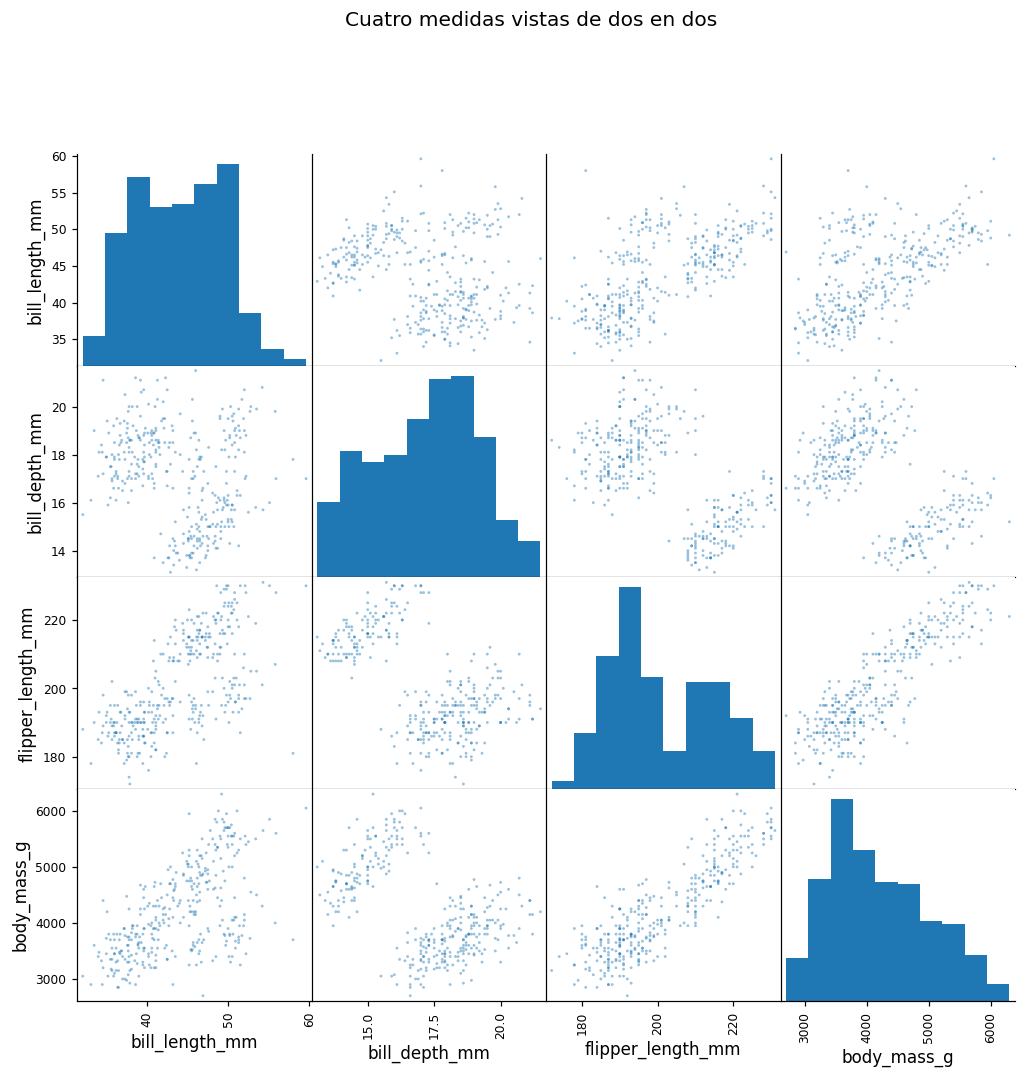

In [5]:
pd.plotting.scatter_matrix(X, figsize=(11, 10), diagonal='hist', alpha=0.45, s=14)
plt.suptitle('Cuatro medidas vistas de dos en dos', y=1.01)
plt.show()


## 3. La trampa de las unidades
La varianza mide cuánto se dispersan los valores alrededor de su media.

$$\mu_j=\frac{1}{n}\sum_{i=1}^{n}x_{ij},\qquad s_{0j}^2=\frac{1}{n}\sum_{i=1}^{n}(x_{ij}-\mu_j)^2.$$

Aquí usamos divisor $n$ para estandarizar, igual que `StandardScaler`. La varianza tiene unidades al cuadrado. Una masa en gramos puede dominar numéricamente sobre una longitud en milímetros.

**Predice** Si cambio gramos por kilogramos sin cambiar ningún animal, ¿cambiará un PCA sin estandarizar?

In [6]:
X_kg = X.copy()
X_kg['body_mass_g'] /= 1000
raw_g = PCA().fit(X)
raw_kg = PCA().fit(X_kg)
display(pd.DataFrame({'Varianza original': X.var(ddof=0),
                      'Peso PC1 con gramos': raw_g.components_[0],
                      'Peso PC1 con kilogramos': raw_kg.components_[0]}).round(3))


,Varianza original,Peso PC1 con gramos,Peso PC1 con kilogramos
bill_length_mm,29.720,0.004,0.265
bill_depth_mm,3.888,-0.001,-0.078
flipper_length_mm,197.154,0.015,0.960
body_mass_g,641250.577,1.000,0.048


## 4. Z-score paso a paso
$$z_{ij}=\frac{x_{ij}-\mu_j}{s_{0j}}.$$

Un z-score de $+1$ significa una desviación estándar por encima de la media de esa variable. El resultado es adimensional. Cada variable tendrá media cero y varianza uno con divisor $n$.

Estandarizar concede igual varianza inicial a las cuatro medidas. Es una decisión de modelado apropiada para esta comparación de unidades diferentes.

In [7]:
mu = X.mean()
centered = X - mu
variance = (centered ** 2).mean()
sigma = np.sqrt(variance)
Z = centered / sigma
trace = pd.DataFrame({'x primer pingüino': X.iloc[0], 'media': mu,
                      'x - media': centered.iloc[0], 'desviación': sigma,
                      'z': Z.iloc[0]})
display(trace.round(4))
display(pd.DataFrame({'Media z': Z.mean(), 'Varianza z (n)': Z.var(ddof=0)}).round(6))
assert np.allclose(Z.mean(), 0)
assert np.allclose(Z.var(ddof=0), 1)


,x primer pingüino,media,x - media,desviación,z
bill_length_mm,39.1,43.9219,-4.8219,5.4516,-0.8845
bill_depth_mm,18.7,17.1512,1.5488,1.9719,0.7854
flipper_length_mm,181.0,200.9152,-19.9152,14.0411,-1.4183
body_mass_g,3750.0,4201.7544,-451.7544,800.7812,-0.5641


,Media z,Varianza z (n)
bill_length_mm,0.0,1.0
bill_depth_mm,0.0,1.0
flipper_length_mm,-0.0,1.0
body_mass_g,0.0,1.0


## 5. Covarianza y correlación
$$C=\frac{Z^\top Z}{n-1},\qquad C_{jk}=\frac{1}{n-1}\sum_i z_{ij}z_{ik}.$$

Productos positivos aparecen cuando las dos variables se alejan de su media en la misma dirección. Productos negativos aparecen cuando lo hacen en direcciones opuestas.

Usamos $n-1$ para la covarianza muestral, compatible con la varianza explicada de `PCA`. Como estandarizamos con divisor $n$, la diagonal de $C$ será $n/(n-1)$, ligeramente mayor que uno. La matriz de correlación será $R=C(n-1)/n$. Este factor común conserva los ejes y los porcentajes de varianza.

,Longitud pico,Profundidad pico,Longitud aleta,Masa corporal
Longitud pico,1.003,-0.236,0.658,0.597
Profundidad pico,-0.236,1.003,-0.586,-0.473
Longitud aleta,0.658,-0.586,1.003,0.874
Masa corporal,0.597,-0.473,0.874,1.003


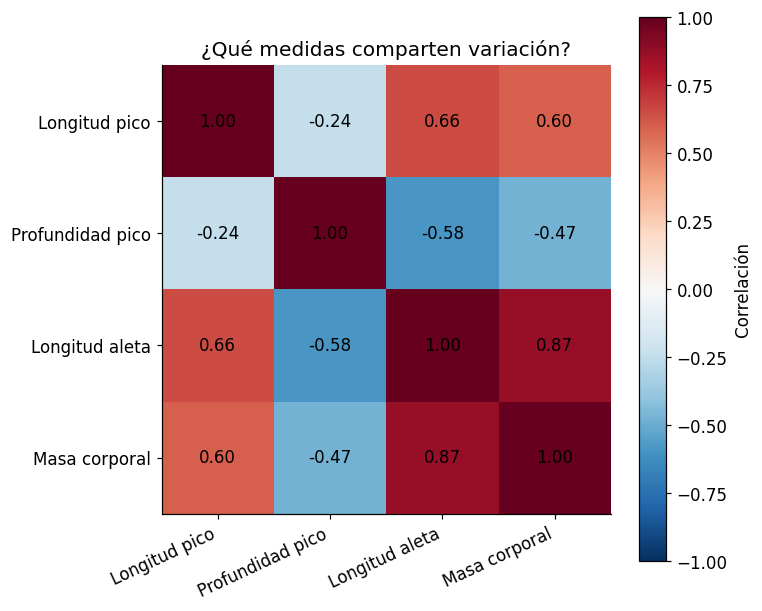

In [8]:
n_samples = len(Z)
C = Z.to_numpy().T @ Z.to_numpy() / (n_samples - 1)
R = C * (n_samples - 1) / n_samples
display(pd.DataFrame(C, index=labels, columns=labels).round(3))
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(R, vmin=-1, vmax=1, cmap='RdBu_r')
ax.set_xticks(range(4), labels, rotation=25, ha='right')
ax.set_yticks(range(4), labels)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f'{R[i,j]:.2f}', ha='center', va='center')
fig.colorbar(im, ax=ax, label='Correlación')
ax.set_title('¿Qué medidas comparten variación?')
plt.tight_layout(); plt.show()


## 6. Encontrar un eje mirando sus sombras
Primero usamos solo aleta y masa estandarizadas. Una dirección unitaria $w=(\cos\theta,\sin\theta)$ produce coordenadas $t=Zw$. Cada coordenada es la proyección de un animal sobre esa dirección.

$$\operatorname{Var}(t)=w^\top Cw,\qquad \|w\|=1.$$

Buscamos la dirección cuya proyección tiene mayor varianza. La restricción de longitud evita aumentar artificialmente la varianza multiplicando el eje por un número enorme.

**Experimento** Ejecuta con `angulo = 0`, luego 45 y 90. Observa los segmentos que conectan cada punto con su proyección.

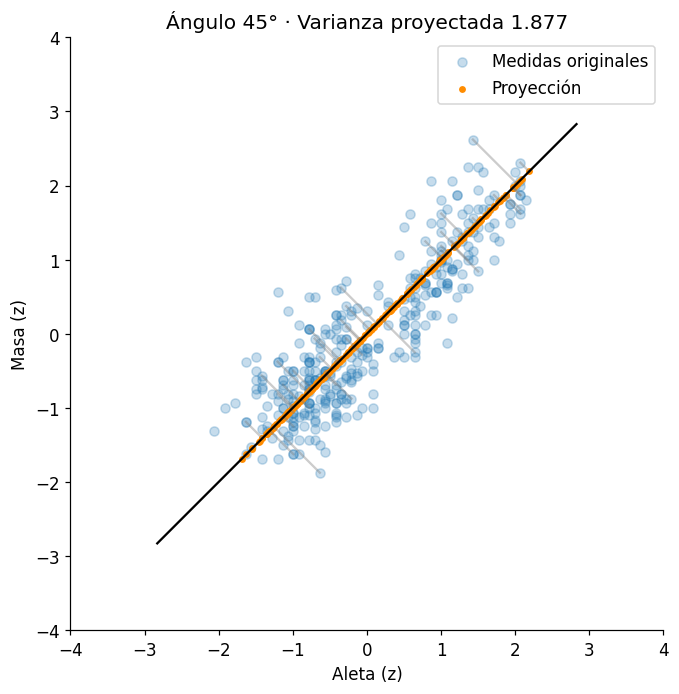

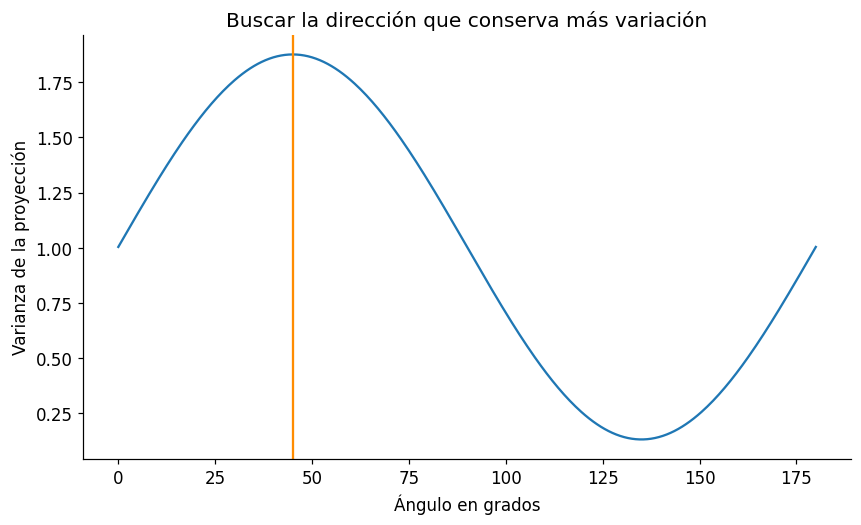

Mejor ángulo de esta búsqueda: 45.0


In [9]:
angulo = 45  # Cambia este número y vuelve a ejecutar
pair = Z[['flipper_length_mm', 'body_mass_g']].to_numpy()
w = np.array([np.cos(np.deg2rad(angulo)), np.sin(np.deg2rad(angulo))])
t = pair @ w
projection = np.outer(t, w)
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(*pair.T, alpha=.25, label='Medidas originales')
ax.scatter(*projection.T, s=12, color='darkorange', label='Proyección')
for point, projected in zip(pair[::8], projection[::8]):
    ax.plot([point[0], projected[0]], [point[1], projected[1]], color='gray', alpha=.4)
ax.plot([-4*w[0], 4*w[0]], [-4*w[1], 4*w[1]], color='black')
ax.set(xlabel='Aleta (z)', ylabel='Masa (z)', xlim=(-4,4), ylim=(-4,4),
       title=f'Ángulo {angulo}° · Varianza proyectada {t.var(ddof=1):.3f}')
ax.set_aspect('equal'); ax.legend(); plt.show()
angles = np.linspace(0, 180, 361)
directions = np.vstack([np.cos(np.deg2rad(angles)), np.sin(np.deg2rad(angles))])
projected_variances = (pair @ directions).var(axis=0, ddof=1)
plt.plot(angles, projected_variances)
plt.axvline(angulo, color='darkorange')
plt.xlabel('Ángulo en grados'); plt.ylabel('Varianza de la proyección')
plt.title('Buscar la dirección que conserva más variación'); plt.show()
print('Mejor ángulo de esta búsqueda:', angles[projected_variances.argmax()])


## 7. PCA manual con las cuatro medidas
La búsqueda anterior se resuelve mediante autovectores y autovalores de la covarianza.

$$Cw_k=\lambda_k w_k.$$

El autovector $w_k$ indica una dirección. El autovalor $\lambda_k$ indica la varianza de los datos proyectados sobre ella. Ordenamos de mayor a menor. Los ejes son ortogonales y sus coordenadas quedan sin correlación lineal.

$$T=ZW,\qquad r_k=\frac{\lambda_k}{\sum_j\lambda_j}.$$

$Z$ tiene tamaño $n\times4$, $W$ tiene tamaño $4\times4$ y $T$ contiene las coordenadas nuevas de cada pingüino. NumPy resuelve la descomposición matricial. El resto del procedimiento queda explícito.

,Varianza,Porcentaje,Acumulado %
PC1,2.762,68.844,68.844
PC2,0.775,19.313,88.157
PC3,0.366,9.131,97.288
PC4,0.109,2.712,100.000


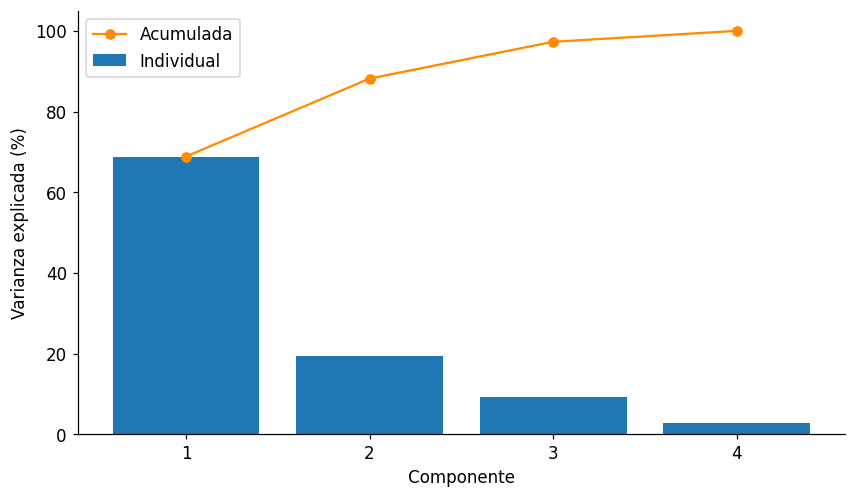

Dos componentes conservan 88.16% de la varianza estandarizada.


In [10]:
eigenvalues, W = np.linalg.eigh(C)
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
W = W[:, order]
# Orientación reproducible: el coeficiente de mayor magnitud queda positivo.
for k in range(4):
    if W[np.abs(W[:, k]).argmax(), k] < 0:
        W[:, k] *= -1
T = Z.to_numpy() @ W
ratios = eigenvalues / eigenvalues.sum()
summary = pd.DataFrame({'Varianza': eigenvalues, 'Porcentaje': ratios*100,
                        'Acumulado %': ratios.cumsum()*100},
                       index=['PC1','PC2','PC3','PC4'])
display(summary.round(3))
plt.bar(range(1,5), ratios*100, label='Individual')
plt.plot(range(1,5), ratios.cumsum()*100, 'o-', color='darkorange', label='Acumulada')
plt.xticks(range(1,5)); plt.xlabel('Componente'); plt.ylabel('Varianza explicada (%)')
plt.legend(); plt.show()
print(f'Dos componentes conservan {100*ratios[:2].sum():.2f}% de la varianza estandarizada.')


## 8. El mapa y la revelación
Primero observa el mapa sin etiquetas. Describe sus estructuras. Después revela la especie.

PCA se ajustó usando únicamente medidas corporales. Colorear después permite evaluar si las estructuras tienen una interpretación biológica. La separación visual puede ser parcial y depende de estos datos.

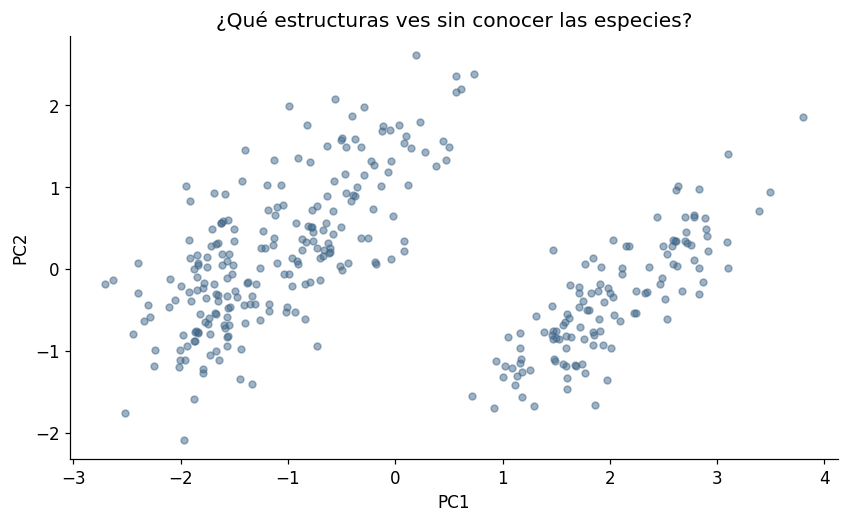

In [11]:
plt.scatter(T[:,0], T[:,1], alpha=.5, s=20, color='#416788')
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.title('¿Qué estructuras ves sin conocer las especies?')
plt.show()


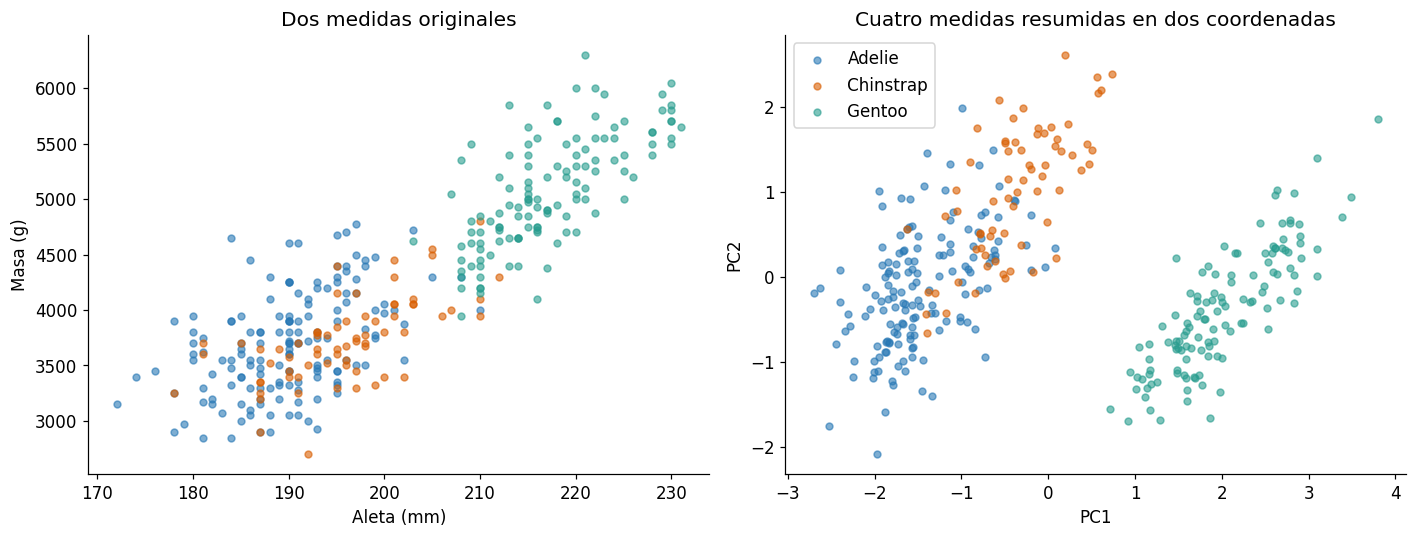

In [12]:
colors = {'Adelie':'#2878B5', 'Chinstrap':'#D95F02', 'Gentoo':'#299D8F'}
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for species, color in colors.items():
    mask = data['species'].eq(species).to_numpy()
    axes[0].scatter(X.loc[mask,'flipper_length_mm'], X.loc[mask,'body_mass_g'],
                    color=color, label=species, alpha=.6, s=20)
    axes[1].scatter(T[mask,0], T[mask,1], color=color, label=species, alpha=.6, s=20)
axes[0].set(xlabel='Aleta (mm)', ylabel='Masa (g)', title='Dos medidas originales')
axes[1].set(xlabel='PC1', ylabel='PC2', title='Cuatro medidas resumidas en dos coordenadas')
axes[1].legend(); plt.tight_layout(); plt.show()


## 9. ¿Qué significan los ejes?
Los coeficientes indican cómo se calcula cada componente. Aquí llamamos **pesos** a los elementos de $W$. La palabra *loadings* tiene distintas convenciones, por eso mostramos además las correlaciones entre variables y componentes.

$$PC_{1,i}=w_{11}z_{i1}+w_{21}z_{i2}+w_{31}z_{i3}+w_{41}z_{i4}.$$

Examina magnitudes y signos conjuntamente. Un eje con aleta y masa positivas y profundidad del pico negativa mezcla tamaño y forma. Un nombre corto es una interpretación aproximada. Cambiar todos los signos de un eje conserva el mismo PCA.

**Pregunta** ¿Qué significa aumentar PC1 manteniendo PC2 fijo? ¿Podemos interpretarlo como aumentar únicamente la masa?

,PC1,PC2
Longitud pico,0.455,0.597
Profundidad pico,-0.400,0.798
Longitud aleta,0.576,0.002
Masa corporal,0.548,0.084


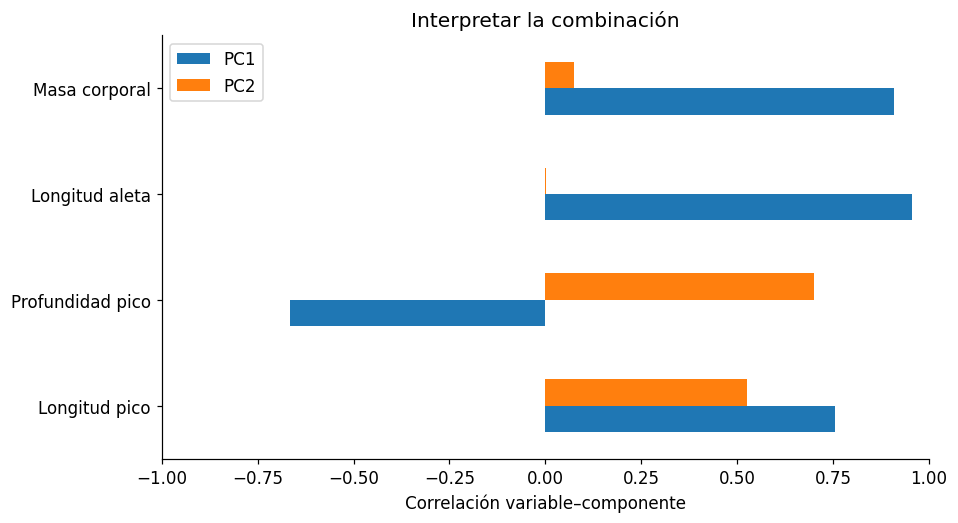

PC1 = +0.455·z(Longitud pico) -0.400·z(Profundidad pico) +0.576·z(Longitud aleta) +0.548·z(Masa corporal)
PC2 = +0.597·z(Longitud pico) +0.798·z(Profundidad pico) +0.002·z(Longitud aleta) +0.084·z(Masa corporal)


In [13]:
weights = pd.DataFrame(W[:,:2], index=labels, columns=['PC1','PC2'])
display(weights.round(3))
for k in range(2):
    print(f'PC{k+1} = ' + ' '.join(f'{W[j,k]:+.3f}·z({labels[j]})' for j in range(4)))
correlations = np.corrcoef(Z.to_numpy().T, T[:,:2].T)[:4,4:]
pd.DataFrame(correlations, index=labels, columns=['PC1','PC2']).plot.barh(xlim=(-1,1))
plt.xlabel('Correlación variable–componente'); plt.title('Interpretar la combinación'); plt.show()


## 10. Reconstruir para ver lo que perdimos
Conservando $q$ componentes podemos aproximar las cuatro medidas originales.

$$\widehat Z=T_qW_q^\top,\qquad \widehat x_{ij}=\widehat z_{ij}s_{0j}+\mu_j.$$

$$MSE_Z=\frac{1}{4n}\sum_{i,j}(z_{ij}-\widehat z_{ij})^2.$$

PCA minimiza el error cuadrático de reconstrucción entre las proyecciones lineales ortogonales de igual dimensión. Aquí el error se mide en el espacio estandarizado. Observa el compromiso entre compresión y fidelidad.

,Componentes,Varianza retenida %,MSE en z
0,1,68.8439,0.3116
1,2,88.1568,0.1184
2,3,97.2877,0.0271
3,4,100.0000,0.0000


,Medida real,Reconstruida,Error
bill_length_mm,39.1,39.50,0.40
bill_depth_mm,18.7,18.68,-0.02
flipper_length_mm,181.0,186.01,5.01
body_mass_g,3750.0,3395.50,-354.50


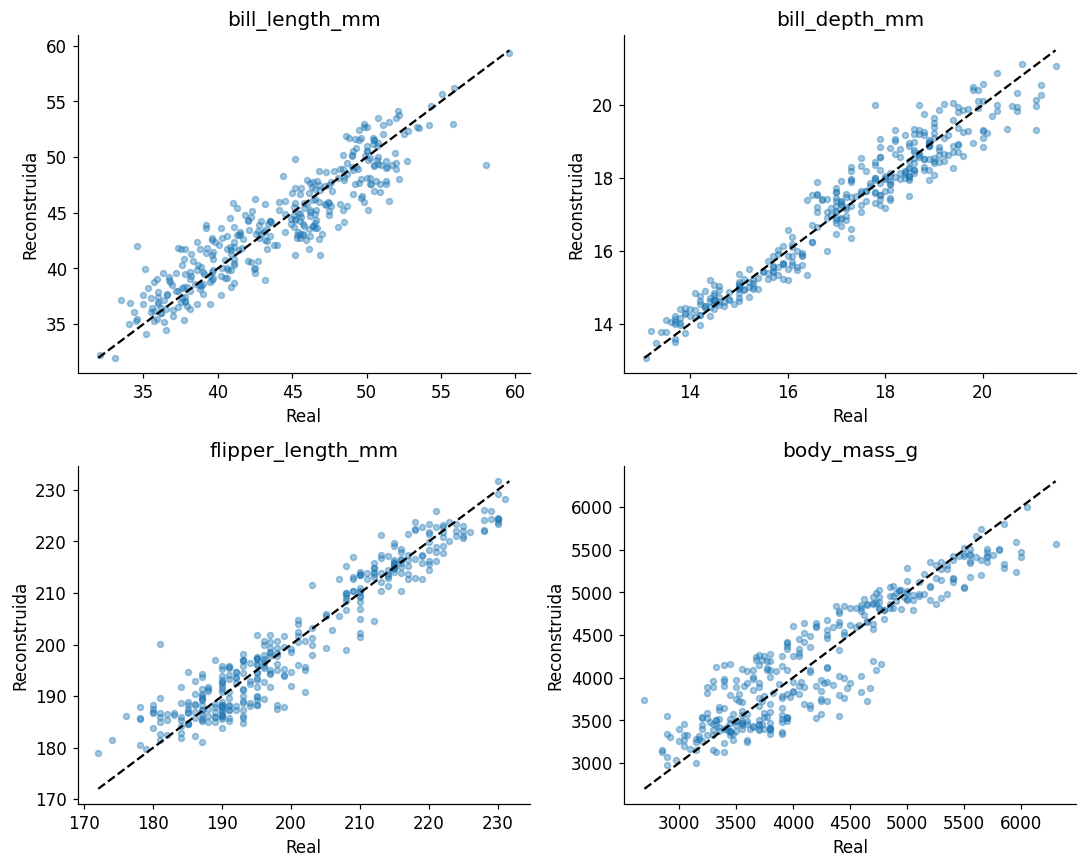

bill_length_mm         2.138775
bill_depth_mm          0.510444
flipper_length_mm      4.125416
body_mass_g          326.735408
dtype: float64

RMSE por variable en su unidad original:


In [14]:
rows = []
for q in range(1,5):
    reconstructed_z = T[:,:q] @ W[:,:q].T
    rows.append([q, ratios[:q].sum()*100, np.mean((Z.to_numpy()-reconstructed_z)**2)])
display(pd.DataFrame(rows, columns=['Componentes','Varianza retenida %','MSE en z']).round(4))
q = 2
Z_hat = T[:,:q] @ W[:,:q].T
X_hat = Z_hat * sigma.to_numpy() + mu.to_numpy()
display(pd.DataFrame({'Medida real': X.iloc[0], 'Reconstruida': X_hat[0],
                      'Error': X_hat[0]-X.iloc[0]}).round(2))
fig, axes = plt.subplots(2,2,figsize=(10,8))
for j, ax in enumerate(axes.flat):
    ax.scatter(X.iloc[:,j], X_hat[:,j], alpha=.4, s=15)
    limits = [min(X.iloc[:,j].min(),X_hat[:,j].min()), max(X.iloc[:,j].max(),X_hat[:,j].max())]
    ax.plot(limits,limits,'k--'); ax.set(title=features[j], xlabel='Real', ylabel='Reconstruida')
plt.tight_layout(); plt.show()
print('RMSE por variable en su unidad original:')
display(pd.Series(np.sqrt(np.mean((X.to_numpy()-X_hat)**2,axis=0)), index=features))
assert np.allclose(rows[-1][2], 0, atol=1e-12)
assert np.isclose(rows[1][2], (1-ratios[:2].sum()))


Guardar dos coordenadas por animal reduce a la mitad las columnas de representación. Para reconstruir también se deben conservar medias, desviaciones y ejes. El ahorro real depende del número de observaciones y de ese coste adicional.

## 11. Verificar todo con scikit-learn
`StandardScaler` aplica la misma estandarización. `PCA` centra la entrada y obtiene los componentes mediante una descomposición numérica. El signo de sus ejes puede diferir, por eso alineamos signos antes de comparar coordenadas.

In [15]:
scaler = StandardScaler()
Z_sklearn = scaler.fit_transform(X)
pca = PCA(n_components=4, svd_solver='full')
T_sklearn = pca.fit_transform(Z_sklearn)
signs = np.sign(np.sum(pca.components_.T * W, axis=0))
T_aligned = T_sklearn * signs
assert np.allclose(Z, Z_sklearn)
assert np.allclose(eigenvalues, pca.explained_variance_)
assert np.allclose(ratios, pca.explained_variance_ratio_)
assert np.allclose(T, T_aligned)
assert np.allclose(C @ W, W * eigenvalues)
assert np.allclose(W.T @ W, np.eye(4))
pca2 = PCA(n_components=2, svd_solver='full')
coordinates = pca2.fit_transform(Z_sklearn)
reconstruction = scaler.inverse_transform(pca2.inverse_transform(coordinates))
assert np.allclose(X_hat, reconstruction)
print('Verificado: z-scores, varianzas, porcentajes, coordenadas, ejes y reconstrucción coinciden.')


Verificado: z-scores, varianzas, porcentajes, coordenadas, ejes y reconstrucción coinciden.


## 12. Actividad de cierre · 10 minutos
1. Elige el menor número de componentes que conserve al menos 90% de la varianza. Justifica tu elección usando la tabla.
2. Explica PC1 usando sus pesos y las unidades estandarizadas.
3. Identifica la variable con peor reconstrucción relativa usando error en z. Explica por qué comparar directamente errores en gramos y milímetros sería problemático.
4. Cambia la masa a kilogramos y verifica que, al estandarizar, los porcentajes se conservan.
5. Un colega afirma que conservar 95% de varianza garantiza 95% de exactitud al predecir especies. Explica el error.


In [16]:
# Espacio de trabajo: completa y ejecuta.
# q_90 = ...
# error_por_variable_z = ...


<details><summary>Solución orientativa · abrir después de discutir</summary>

El número mínimo se obtiene buscando el primer porcentaje acumulado que alcance 90%. La interpretación de PC1 debe incluir tanto los coeficientes positivos como los negativos. El error relativo se calcula como la media de errores cuadrados estandarizados por columna. Gramos y kilogramos producen los mismos z-scores. El porcentaje de varianza describe la dispersión conservada de las entradas, mientras que la exactitud predictiva requiere etiquetas y evaluación con datos separados.

</details>

In [17]:
q_90 = np.searchsorted(ratios.cumsum(), .90) + 1
print('Componentes para 90%:', q_90)
display(pd.Series(np.mean((Z.to_numpy()-Z_hat)**2,axis=0), index=features,
                  name='MSE estandarizado').sort_values(ascending=False))
assert np.allclose(StandardScaler().fit_transform(X_kg), Z_sklearn)


body_mass_g          0.166481
bill_length_mm       0.153916
flipper_length_mm    0.086324
bill_depth_mm        0.067008
Name: MSE estandarizado, dtype: float64

Componentes para 90%: 3


## 13. Extensión opcional · Aplicar lo aprendido a predicción
La utilidad demostrada en esta clase es resumir, visualizar y reconstruir. Para evaluar predicción se necesita otro experimento. Este ejemplo compara una regresión logística con cuatro medidas frente a dos componentes. El escalado y PCA se ajustan dentro de cada partición de entrenamiento para evitar fuga de información. La especie entra únicamente como objetivo supervisado en esta extensión.

Las particiones aleatorias evalúan generalización dentro de esta muestra. Aplicar el modelo a otras islas o años requeriría un diseño de validación adecuado a ese objetivo.

In [18]:
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
models = {
    'Cuatro medidas': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    'Dos componentes': make_pipeline(StandardScaler(), PCA(n_components=2),
                                    LogisticRegression(max_iter=1000))
}
results = []
for name, model in models.items():
    scores = cross_val_score(model, X, data['species'], cv=cv, scoring='accuracy')
    results.append([name, scores.mean(), scores.std()])
display(pd.DataFrame(results, columns=['Representación','Accuracy media','Desviación entre folds']))


,Representación,Accuracy media,Desviación entre folds
0,Cuatro medidas,0.988278,0.010994
1,Dos componentes,0.897783,0.025695


## Recursos visuales para preparar las diapositivas
- **Explained Visually — Principal Component Analysis**, Victor Powell y Lewis Lehe. Exploración visual de proyecciones y direcciones. Ideal para acompañar la sección 6. https://setosa.io/ev/principal-component-analysis/
- **Palmer Penguins**, Allison Horst, Alison Hill y Kristen Gorman. Documentación, ilustraciones de especies y definición de las medidas. https://allisonhorst.github.io/palmerpenguins/
- **StandardScaler**. Referencia de estandarización y convención del divisor. https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html
- **PCA**. Referencia de componentes, varianza explicada y transformación inversa. https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html

Los gráficos de este notebook se generan a partir de los datos y puedes exportarlos para tus diapositivas con `fig.savefig("grafico.png", dpi=200, bbox_inches="tight")` antes de `plt.show()`. Para reutilizar ilustraciones externas revisa sus condiciones de atribución.

**Discusión final** ¿Aceptarías perder el significado directo de cuatro columnas para obtener un mapa compacto? Justifica tu decisión para exploración, compresión y explicación de decisiones individuales.